# Q-Learning vs Policy Gradient on Stochastic FrozenLake

This notebook runs the existing two-algorithm comparison. The agent implementations are imported from `q_learning.py` and `policy_gradient.py`. It uses the default sparse FrozenLake reward and does not use custom reward shaping.

## Configuration

Environment: `FrozenLake-v1`, 8x8, slippery transitions enabled. Training: 1,000 episodes per agent; Q-Learning learning rate 0.1; Policy Gradient learning rate 0.01; discount factor 0.99 for both.

In [ ]:
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np

from policy_gradient import PolicyGradientAgent
from q_learning import QLearningAgent

NUM_EPISODES = 1000
GAMMA = 0.99

env = gym.make("FrozenLake-v1", map_name="8x8", is_slippery=True)
q_agent = QLearningAgent(env, alpha=0.1, gamma=GAMMA, epsilon=0.1)
policy_agent = PolicyGradientAgent(env, learning_rate=0.01, gamma=GAMMA)

print("Q-table shape:", q_agent.Q.shape)
print("Policy shape:", policy_agent.policy.shape)


Q-table shape: (64, 4)
Policy shape: (64, 4)


Q-Learning mean training reward: 0.0000
Policy Gradient mean training reward: 0.0010


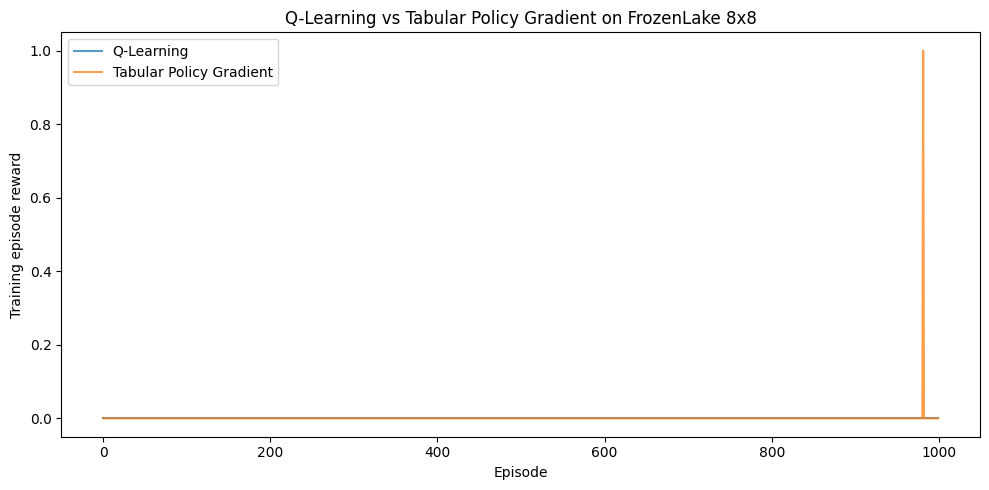

In [ ]:
q_rewards = q_agent.train(NUM_EPISODES)
policy_rewards = policy_agent.train(NUM_EPISODES)

print(f"Q-Learning mean training reward: {np.mean(q_rewards):.4f}")
print(f"Policy Gradient mean training reward: {np.mean(policy_rewards):.4f}")

plt.figure(figsize=(10, 5))
plt.plot(q_rewards, label="Q-Learning", alpha=0.75)
plt.plot(policy_rewards, label="Tabular Policy Gradient", alpha=0.75)
plt.xlabel("Episode")
plt.ylabel("Training episode reward")
plt.title("Q-Learning vs Tabular Policy Gradient on FrozenLake 8x8")
plt.legend()
plt.tight_layout()
plt.show()

env.close()